# 09 Reinforcement learning: learning from a score that comes at the end

*Teaching material. Not for clinical use.*

A policy for treating sepsis was learned from the records of 17,083 admissions in one hospital's database and tested on 79,073 admissions from 128 hospitals (E-120). Scored from records by weighted importance sampling, its estimated value was 84.5 against 56.9 for the clinicians. Critics then scored, by importance sampling, a policy that gave no drugs at all, and in most of their reproductions it beat the clinician policy too (E-50).

**Before reading on, guess.** What went wrong?

- Nothing: the learned policy is better than the clinicians, and so is giving no drugs
- The clinicians were treating the wrong patients
- The way the policies were scored can reward withholding treatment
- There were too few records

Write the guess down. It is not marked, and the answer comes in the failure section below.

**What stands in for what.** Prolonged care of a casualty who cannot be evacuated is a sequence of decisions under uncertainty: fluid, blood, drugs, when to re-examine. No open data exist for it, so sepsis stands in for it here, and none of the sepsis studies quoted is of casualties. A second stand-in sits inside the first. The decision process this notebook learns on is **constructed** in the library, and every number in it is an assumption. It is not ICU-Sepsis (E-49), the published benchmark, whose figures are quoted only as published. Nothing in this notebook says anything about a patient.

**What bounds the actions.** Lens 08's knowledge graph answers a query for what can be done at a given echelon: every intervention whose competency is held by a role available there, with the edges that place it. A policy for prolonged care could consider only those actions. That bound is described here and is not built into this lens: the constructed process offers the same three doses at every step.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from inference_labs import baseline, generator
from inference_labs.lenses import decision, rules
from inference_labs.lenses import reinforcement as rl

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 11, "axes.titleweight": "bold", "font.size": 9})
DARK, LIGHT, MID, PALE, GREY = "#7f2704", "#d9d9d9", "#08306b", "#6baed6", "#969696"
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", None)

## The idea, before any medicine

A courier learns her way across a city she does not know. Nobody tells her at each junction whether the turn was a good one; she finds out only at the end, when the parcel arrives in time or does not. Over many days she comes to prefer the turns that led somewhere good, and if you ask her how good a junction is, she answers with how things usually turned out from there. Now suppose her manager wants to know whether a new plan, *always take the back road*, is any good, without sending anyone down it. He reads the couriers' logbooks and counts only the days on which somebody happened to take the back road. If couriers took it only on quiet days, the plan looks wonderful.

**Plain.** You try, see what follows, and prefer what led somewhere good. The value of a place is how things usually turn out from there if you keep choosing well, and the value of a choice is the value of where it leads. The danger is learning to please the scorer instead of doing the job. When a policy can only be scored from records of what other people did, the records speak only for the choices those people made, in the situations in which they made them.

**Developer.** A policy is a table: for each state, here a severity and a step, one dose. Learning from logs, not from free interaction:

```python
counts[severity, dose, next_state] += 1                 # for every logged step: where each dose led
P = counts / counts.sum(axis=-1)                        # the learner's model of the process
V = ones(n_severities)                                  # after the last step, still in care counts as surviving
for step in reversed(range(steps)):                     # the Bellman equation, worked backwards
    Q = P[:, :, in_care] @ V + P[:, :, recovered]       # the value of each dose at each severity
    policy[step], V = Q.argmax(axis=1), Q.max(axis=1)
```

Scoring a policy from the same logs, by weighted importance sampling:

```python
w[episode] = product(policy_chance(dose | state) / clinicians_chance(dose | state) for each logged step)
estimate = sum(w * survived) / sum(w)
effective_sample = sum(w) ** 2 / sum(w ** 2)
```

Each is one pass over the logs.

**Technical.** A finite-horizon Markov decision process has states $s$, actions $a$, transition probabilities $P(s' \mid s, a)$, a reward of 1 for surviving and 0 for dying, and a horizon of $H$ steps. The value of a state with $k$ steps left under policy $\pi$ satisfies the Bellman equation $V_k^\pi(s) = \sum_a \pi(a \mid s) \sum_{s'} P(s' \mid s, a)\, V_{k-1}^\pi(s')$, with $V_0 = 1$ for a patient still in care, 1 for one recovered and 0 for one dead; the best policy takes the maximum over $a$ in place of the average. Offline, $P$ is replaced by counts from logged episodes of a behaviour policy $\mu$. Off-policy evaluation by weighted importance sampling estimates the value of $\pi$ as $\hat V = \sum_i w_i G_i / \sum_i w_i$, with $w_i = \prod_t \pi(a_{it} \mid s_{it}) / \hat\mu(a_{it} \mid s_{it})$ and $G_i$ the return of episode $i$; the effective sample size is $(\sum_i w_i)^2 / \sum_i w_i^2$. The estimate rests on three assumptions: the recorded state holds everything that drove both $\mu$ and the outcome; $\mu(a \mid s) > 0$ wherever $\pi(a \mid s) > 0$; and the state at each step holds nothing recorded after the action. The constructed process meets the first by construction, and is made to break the second in the failure and the third in the treatment case.

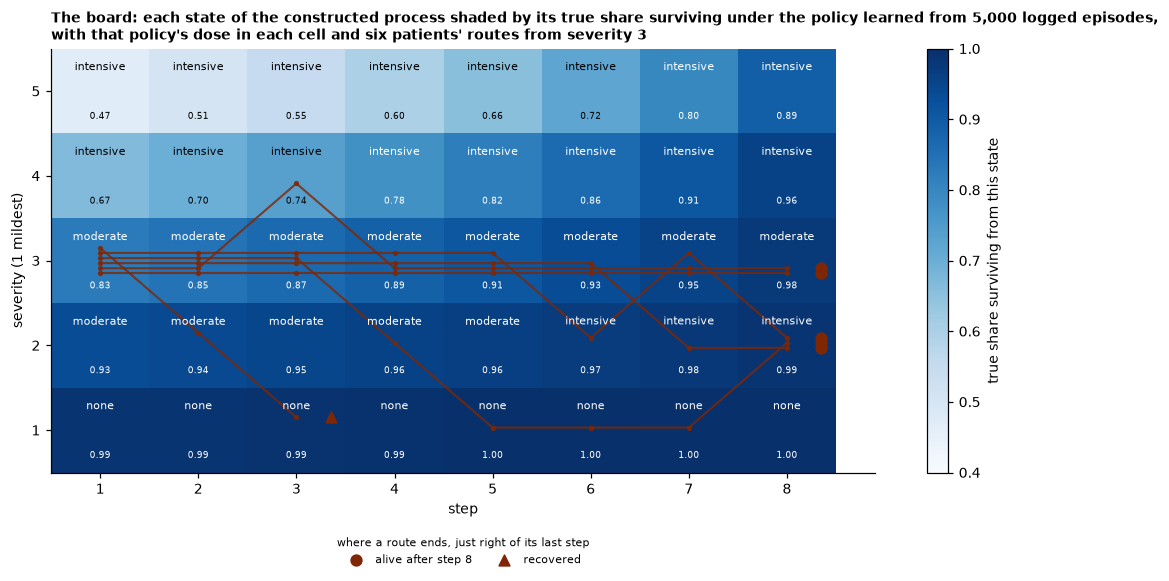

Learned from 5,000 logged episodes: true share surviving 0.829; the best policy, from the process's own tables, 0.834; the two policies give a different dose in 11 of the 40 cells (constructed).


In [2]:
# Central figure: the board. The control: change it and run the cell again.
LOGGED_FOR_BOARD = 5_000     # logged episodes the learner is given (seed 42); try 500

learned = rl.learned_from(LOGGED_FOR_BOARD)
grid = rl.value_grid(learned.policy)[:rl.STEPS, :, 0]          # true share surviving from each state
fig, ax = plt.subplots(figsize=(10, 5.4))
image = ax.imshow(grid.T, origin="lower", cmap="Blues", vmin=0.4, vmax=1.0, aspect="auto",
                  extent=(0.5, rl.STEPS + 0.5, 0.5, rl.S + 0.5))
for t in range(rl.STEPS):
    for s in range(rl.S):
        ax.text(t + 1, s + 1 + 0.28, rl.DOSES[learned.table[t, s]], ha="center", va="center", fontsize=7,
                color="white" if grid[t, s] > 0.75 else "black")
        ax.text(t + 1, s + 1 - 0.3, f"{grid[t, s]:.2f}", ha="center", va="center", fontsize=6,
                color="white" if grid[t, s] > 0.75 else "black")
ends = {"recovered": ("^", "recovered"), "died": ("X", "died"), "alive at the end": ("o", "alive after step 8")}
seen = set()
for k, path in enumerate(rl.routes(learned.policy, start=3, n=6)):
    offset = (k - 2.5) * 0.06
    xs = np.arange(1, len(path["severities"]) + 1)
    ys = np.array(path["severities"]) + offset
    ax.plot(xs, ys, color=DARK, linewidth=1.4, alpha=0.8, marker=".", markersize=5)
    marker, label = ends[path["end"]]
    ax.scatter(xs[-1] + 0.35, ys[-1], marker=marker, s=50, color=DARK, zorder=3,
               label=label if label not in seen else None)
    seen.add(label)
ax.set_xticks(range(1, rl.STEPS + 1))
ax.set_yticks(rl.SEVERITIES)
ax.set_xlabel("step")
ax.set_ylabel("severity (1 mildest)")
ax.set_xlim(0.5, rl.STEPS + 0.9)
fig.colorbar(image, ax=ax, label="true share surviving from this state")
ax.legend(fontsize=7, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=3,
          title="where a route ends, just right of its last step", title_fontsize=7)
ax.set_title(f"The board: each state of the constructed process shaded by its true share surviving under the policy "
             f"learned from {LOGGED_FOR_BOARD:,} logged episodes,\nwith that policy's dose in each cell and six "
             f"patients' routes from severity 3", loc="left", fontsize=9)
plt.tight_layout()
plt.show()
table_best, value_best = rl.best()
print(f"Learned from {LOGGED_FOR_BOARD:,} logged episodes: true share surviving {rl.true_value(learned.policy):.3f}; "
      f"the best policy, from the process's own tables, {value_best:.3f}; the two policies give a different dose in "
      f"{int((learned.table != table_best).sum())} of the {rl.STEPS * rl.S} cells (constructed).")

Each cell is a state: a severity, from 1 at the bottom to 5 at the top, at one of eight steps. The shade and the lower number are the true share surviving from that state for a patient in care there, if the learned policy is followed from then on; the word is the dose the policy gives there. Value falls with severity, and it rises towards the right because fewer steps remain in which to die. The dark lines are six patients started at severity 3 and treated by the learned policy: each moves up, down or stays at every step, and leaves the board when it recovers or dies.

The shading is known only because the process is constructed: its own tables give the true value of every state. A learner given only logs never sees this board. It sees records of what the clinicians did and what followed, and it has to estimate the board from them. Change `LOGGED_FOR_BOARD` to 500 and run the cell again: with fewer records the learned doses change, and the printed comparison with the best policy shows by how much.

## By hand: four states, two actions, two steps

A patient is **critical** or **unwell**, and an episode ends at **recovered**, worth 1, or **dead**, worth 0. At each step the clinician can **wait** or **treat**. The chances are chosen to be easy to work with; this world is constructed.

| From | Action | Where it leads |
|---|---|---|
| critical | wait | critical 1/2, dead 1/2 |
| critical | treat | unwell 1/2, critical 1/4, dead 1/4 |
| unwell | wait | recovered 1/2, unwell 1/4, critical 1/4 |
| unwell | treat | recovered 1/2, unwell 1/4, dead 1/4 |

There are two steps. A patient still critical or unwell after the second counts as surviving, worth 1, as in the constructed process above.

**One step left.** The value of an action is the chance-weighted value of where it leads. From critical: wait gives 1/2 × 1 + 1/2 × 0 = 1/2, and treat gives 1/2 × 1 + 1/4 × 1 + 1/4 × 0 = 3/4. Treat, worth 3/4. From unwell: wait gives 1/2 × 1 + 1/4 × 1 + 1/4 × 1 = 1, and treat gives 1/2 × 1 + 1/4 × 1 + 1/4 × 0 = 3/4. Wait, worth 1.

**Two steps left.** Now each place an action leads to is worth what the step before found. From critical: wait gives 1/2 × 3/4 + 1/2 × 0 = 3/8, and treat gives 1/2 × 1 + 1/4 × 3/4 + 1/4 × 0 = 11/16. Treat, worth 11/16. From unwell: wait gives 1/2 × 1 + 1/4 × 1 + 1/4 × 3/4 = 15/16, and treat gives 1/2 × 1 + 1/4 × 1 + 1/4 × 0 = 3/4. Wait, worth 15/16.

So: treat the critical patient and wait for the unwell one. Waiting risks a slide back to critical; treating the unwell risks death; the sums say which risk is worse. That is the Bellman equation: the value of a state is the best, over actions, of the chance-weighted value of the states each action leads to, worked backwards from the end.

In [3]:
# The same in plain Python, with fractions so that nothing is rounded
from fractions import Fraction as F

moves = {
    "critical": {"wait": {"critical": F(1, 2), "dead": F(1, 2)},
                 "treat": {"unwell": F(1, 2), "critical": F(1, 4), "dead": F(1, 4)}},
    "unwell": {"wait": {"recovered": F(1, 2), "unwell": F(1, 4), "critical": F(1, 4)},
               "treat": {"recovered": F(1, 2), "unwell": F(1, 4), "dead": F(1, 4)}},
}
end = {"recovered": F(1), "dead": F(0)}
value = {"critical": F(1), "unwell": F(1)}            # no steps left: still in care counts as surviving
for left in (1, 2):
    q = {s: {a: sum(p * end.get(n, value.get(n)) for n, p in where.items()) for a, where in acts.items()}
         for s, acts in moves.items()}
    value = {s: max(q[s].values()) for s in q}
    for s in q:
        print(f"{left} step(s) left, {s}: wait {q[s]['wait']}, treat {q[s]['treat']}; best {max(q[s], key=q[s].get)}")
by_hand = value

1 step(s) left, critical: wait 1/2, treat 3/4; best treat
1 step(s) left, unwell: wait 1, treat 3/4; best wait
2 step(s) left, critical: wait 3/8, treat 11/16; best treat
2 step(s) left, unwell: wait 15/16, treat 3/4; best wait


In [4]:
library = rl.toy_values()
display(library)
final = library[library["steps left"] == rl.TOY_STEPS].set_index("state")["value"]
print("The library agrees with the hand count and the plain Python:",
      all(final[s] == float(by_hand[s]) for s in by_hand))

,steps left,state,value if wait,value if treat,best,value
0,1,critical,0.500,0.750,treat,0.750
1,1,unwell,1.000,0.750,wait,1.000
2,2,critical,0.375,0.688,treat,0.688
3,2,unwell,0.938,0.750,wait,0.938


The library agrees with the hand count and the plain Python: True


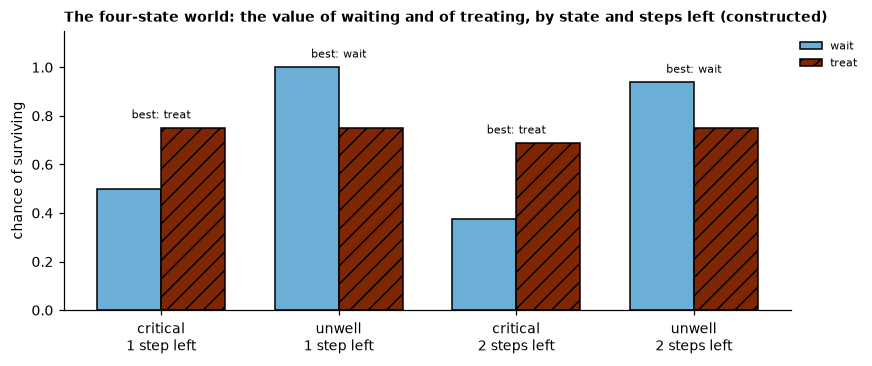

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.4))
labels, x = [], 0
for left in (1, 2):
    for state in ("critical", "unwell"):
        row = library[(library["steps left"] == left) & (library["state"] == state)].iloc[0]
        ax.bar(x - 0.18, row["value if wait"], width=0.36, color=PALE, edgecolor="black",
               label="wait" if x == 0 else None)
        ax.bar(x + 0.18, row["value if treat"], width=0.36, color=DARK, edgecolor="black", hatch="//",
               label="treat" if x == 0 else None)
        ax.text(x, max(row["value if wait"], row["value if treat"]) + 0.04, f"best: {row['best']}", ha="center",
                fontsize=7)
        labels.append(f"{state}\n{left} step{'s' if left > 1 else ''} left")
        x += 1
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels)
ax.set_ylim(0, 1.15)
ax.set_ylabel("chance of surviving")
ax.legend(fontsize=7, frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))
ax.set_title("The four-state world: the value of waiting and of treating, by state and steps left (constructed)",
             loc="left", fontsize=9)
plt.tight_layout()
plt.show()

## Diagnosis: which question next

This section is about a diagnosis, and its results are kept apart from the treatment results below. The fit is **weak**: reinforcement learning is built for sequences of decisions whose reward comes later, and triage is one short sequence of questions whose reward, right or wrong, comes at once.

The MPTT-24 asks its questions in a fixed order and stops at the first exit (E-08). The generator records five of them: catastrophic haemorrhage, walking, conscious level, respiratory rate 12 to 23, and heart rate below 100. It records no breathing check, which the coded rule takes as passed for everyone. Here a policy chooses which of the five to ask next, and when to stop and decide whether to flag the casualty as needing a life-saving intervention.

Stopping costs the expected cost of the decision: a miss weighed nine times a false alarm, lens 10's default, so the policy flags when the share in need is at least 0.10. Asking costs a little: 0.01 of a false alarm for each question. Both costs are assumptions, and the policy's results rest on them. The value of asking is minus its cost plus the expected value of where the answer leads: the Bellman equation again, solved over every state of knowledge the training sample holds, with the chances counted on lens 02's training sample of 100,000 synthetic casualties (seed 7). The policy is then scored on the 100,000 synthetic casualties of the military cohort (seed 42), every stream, against need for a life-saving intervention (mechanism).

In [6]:
tree = rl.question_tree()
display(tree.rename(columns={"casualties": "training casualties"}))
print(f"The policy has {len(tree)} routes; it asks at most {tree['route'].str.count('>').max() + 1} questions, and "
      f"heart rate is asked on {int(tree['route'].str.contains('heart rate').sum())} of them.")

,route,decision,training casualties,share in need
0,walking: no,flag,50841,0.238
1,walking: yes > respiratory rate 12 to 23: yes > conscious level: alert > catastrophic haemorrhage: no,do not flag,35673,0.052
2,walking: yes > respiratory rate 12 to 23: no,flag,12096,0.194
3,walking: yes > respiratory rate 12 to 23: yes > conscious level: responds to voice,flag,1275,0.177
4,walking: yes > respiratory rate 12 to 23: yes > conscious level: alert > catastrophic haemorrhage: yes,flag,115,1.000


The policy has 5 routes; it asks at most 4 questions, and heart rate is asked on 0 of them.


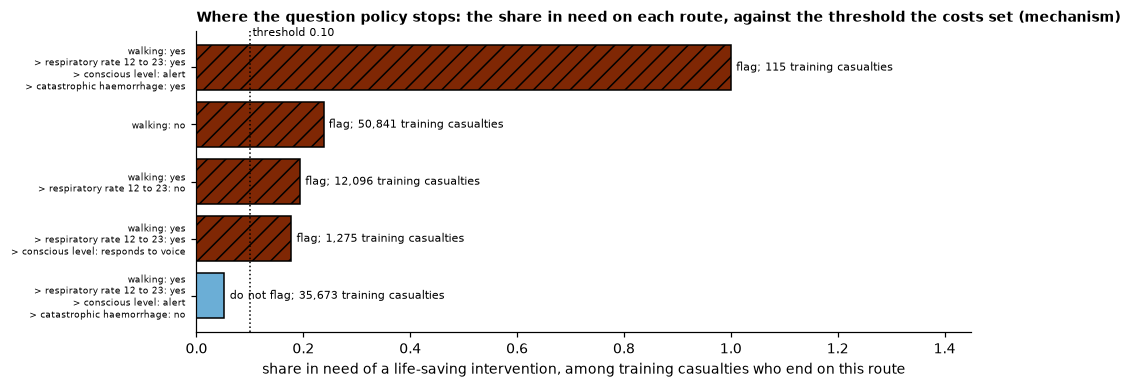

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.6))
t = decision.threshold()
order = tree.sort_values("share in need")
for y, (_, row) in enumerate(order.iterrows()):
    flagged = row["decision"] == rl.FLAG
    ax.barh(y, row["share in need"], color=DARK if flagged else PALE, edgecolor="black", hatch="//" if flagged else "")
    ax.text(row["share in need"] + 0.01, y, f"{row['decision']}; {row['casualties']:,} training casualties",
            va="center", fontsize=7)
ax.axvline(t, color="black", linestyle=":", linewidth=1)
ax.text(t + 0.005, len(order) - 0.45, f"threshold {t:.2f}", fontsize=7)
ax.set_yticks(range(len(order)))
ax.set_yticklabels([r.replace(" > ", "\n> ") for r in order["route"]], fontsize=6)
ax.set_xlim(0, 1.45)
ax.set_xlabel("share in need of a life-saving intervention, among training casualties who end on this route")
ax.set_title("Where the question policy stops: the share in need on each route, against the threshold the costs set "
             "(mechanism)", loc="left", fontsize=9)
plt.tight_layout()
plt.show()

The policy asks about walking first, as the MPTT-24 does after its catastrophic haemorrhage step. A casualty who is not walking is flagged at once: about a quarter of such casualties in the training sample are in need, well above 0.10, and no answer to a further question would bring enough of them below the line to be worth its cost. A walking casualty is asked whether the respiratory rate is 12 to 23, then about conscious level, then about catastrophic haemorrhage, and is left unflagged only after passing all three. Heart rate is never asked at this cost. The rule asks in a fixed order and its exits were set in advance (E-08); the policy's order comes from the counts and the costs.

The cell below scores both on the evaluation sample, with each comparison repeated on 20 further samples of 100,000.

In [8]:
res = rl.diagnosis_results()
m = res["measures"]
shown = pd.DataFrame(m).T[["sensitivity", "specificity", "brier", "calibration", "net benefit", "questions"]]
shown.columns = ["sensitivity", "specificity", "Brier score", "share in need where stopped (or flagged) less share in need",
                 "net benefit per 100 at 0.10", "questions asked"]
display(shown.map(lambda v: f"{v:.4f}"))
sp = rl.diagnosis_spread()
measures = (("sensitivity", 3, ""), ("specificity", 3, ""), ("brier", 3, ""), ("calibration", 3, ""),
            ("net benefit", 1, " per 100"), ("questions", 2, ""))
labels = dict(zip([key for key, _, _ in measures], shown.columns))
for other in (rl.FIGURE, rl.TEXT):
    for group, words in (("", "every stream"), (", battle", "battle casualties alone")):
        print(f"Question policy less the {other}, {words}, across {len(sp)} further samples:")
        for measure, places, unit in measures:
            print(f"  {labels[measure]}: {rl.spread_words(rl.less(sp, measure, other, group), places, unit)}")
print()
print(rules.d23_sentence())
print(rl.HOSPITAL + ".")

,sensitivity,specificity,Brier score,share in need where stopped (or flagged) less share in need,net benefit per 100 at 0.10,questions asked
question policy,0.8843,0.4023,0.1311,-0.0001,9.2388,2.2132
"question policy, battle",0.8982,0.3748,0.3273,-0.3120,41.6118,1.9004
"MPTT-24, figure (as published)",0.5999,0.7856,0.2454,0.1118,8.0366,3.2899
"MPTT-24, figure (as published), battle",0.6267,0.7387,0.3175,-0.0571,29.9987,3.3297
"MPTT-24, text (as validated)",0.6144,0.7780,0.2493,0.1205,8.2081,3.2558
"MPTT-24, text (as validated), battle",0.6414,0.7314,0.3137,-0.0461,30.7005,3.2700


Question policy less the MPTT-24, figure (as published), every stream, across 20 further samples:
  sensitivity: higher: the difference runs from +0.282 to +0.295 across 20 seeds
  specificity: lower: the difference runs from -0.385 to -0.380 across 20 seeds
  Brier score: lower: the difference runs from -0.116 to -0.110 across 20 seeds
  share in need where stopped (or flagged) less share in need: lower: the difference runs from -0.112 to -0.107 across 20 seeds
  net benefit per 100 at 0.10: higher: the difference runs from +1.1 to +1.5 per 100 across 20 seeds
  questions asked: lower: the difference runs from -1.08 to -1.06 across 20 seeds
Question policy less the MPTT-24, figure (as published), battle casualties alone, across 20 further samples:
  sensitivity: higher: the difference runs from +0.271 to +0.286 across 20 seeds
  specificity: lower: the difference runs from -0.369 to -0.356 across 20 seeds
  Brier score: higher: the difference runs from +0.002 to +0.013 across 20 seeds

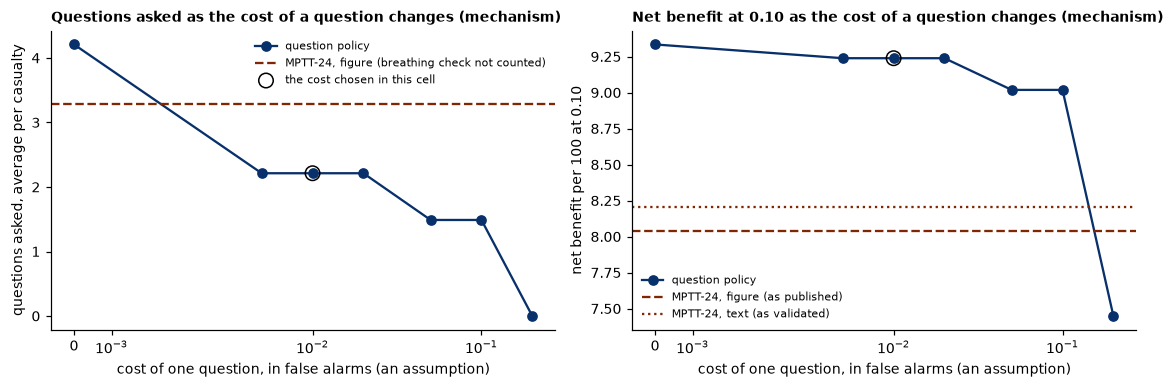

At a cost of 0.01 per question the policy asks 2.21 questions on average, first walking; sensitivity 0.884, specificity 0.402.


,route,decision,training casualties,share in need
0,walking: no,flag,50841,0.238
1,walking: yes > respiratory rate 12 to 23: yes > conscious level: alert > catastrophic haemorrhage: no,do not flag,35673,0.052
2,walking: yes > respiratory rate 12 to 23: no,flag,12096,0.194
3,walking: yes > respiratory rate 12 to 23: yes > conscious level: responds to voice,flag,1275,0.177
4,walking: yes > respiratory rate 12 to 23: yes > conscious level: alert > catastrophic haemorrhage: yes,flag,115,1.000


In [9]:
# The control: the cost of a question, in false alarms. Change it and run the cell again.
QUESTION_COST = rl.QUESTION_COST       # 0.01; try 0, 0.05 or 0.2

curve = rl.cost_curve(tuple(sorted(set(rl.COST_GRID) | {QUESTION_COST})))
chosen = curve.loc[QUESTION_COST]
rule = res["measures"]
fig, (ax, bx) = plt.subplots(1, 2, figsize=(10.5, 3.6))
ax.plot(curve.index, curve["questions asked"], marker="o", color=MID, label="question policy")
ax.axhline(rule[rl.FIGURE]["questions"], color=DARK, linestyle="--", label="MPTT-24, figure (breathing check not counted)")
ax.scatter([QUESTION_COST], [chosen["questions asked"]], s=90, facecolors="none", edgecolors="black", zorder=3,
           label="the cost chosen in this cell")
ax.set_xscale("symlog", linthresh=0.005)
ax.set_xlabel("cost of one question, in false alarms (an assumption)")
ax.set_ylabel("questions asked, average per casualty")
ax.legend(fontsize=7, frameon=False)
ax.set_title("Questions asked as the cost of a question changes (mechanism)", loc="left", fontsize=9)
bx.plot(curve.index, curve["net benefit"], marker="o", color=MID, label="question policy")
bx.axhline(rule[rl.FIGURE]["net benefit"], color=DARK, linestyle="--", label="MPTT-24, figure (as published)")
bx.axhline(rule[rl.TEXT]["net benefit"], color=DARK, linestyle=":", label="MPTT-24, text (as validated)")
bx.scatter([QUESTION_COST], [chosen["net benefit"]], s=90, facecolors="none", edgecolors="black", zorder=3)
bx.set_xscale("symlog", linthresh=0.005)
bx.set_xlabel("cost of one question, in false alarms (an assumption)")
bx.set_ylabel("net benefit per 100 at 0.10")
bx.legend(fontsize=7, frameon=False)
bx.set_title("Net benefit at 0.10 as the cost of a question changes (mechanism)", loc="left", fontsize=9)
plt.tight_layout()
plt.show()
print(f"At a cost of {QUESTION_COST:g} per question the policy asks {chosen['questions asked']:.2f} questions on average, "
      f"first {chosen['first question']}; sensitivity {chosen['sensitivity']:.3f}, specificity {chosen['specificity']:.3f}.")
display(rl.question_tree(QUESTION_COST).rename(columns={"casualties": "training casualties"}))

Read the comparison with its assumptions in view. The policy is built to minimise the expected cost that net benefit at 0.10 scores, so its higher net benefit is a win on its own measure, on the generator, whose signs are assumptions tuned to a rule's accuracy measured on hospital observations. It buys that by flagging far more casualties who are not in need: its specificity is lower than the rule's on every one of the 20 samples. Its shares in need are counted on every stream of the training sample, so they are well calibrated there; among battle casualties alone, where far more are in need, its Brier score is higher than the rule's on every sample, and the comparison that favours it on every stream reverses. The policy asks fewer questions than the rule, and asks them in a different order, but its order is a product of the costs: set a question's cost to zero and it asks about four on average.

**Teach back.** In one sentence, what does the Bellman equation say a question is worth?

## Treatment: learning a policy from logs, scoring it from logs, then the truth

This section is about a treatment, and its results are kept apart from the diagnosis results above.

The treatment case runs on the constructed process, not on the generator's casualties. A patient has a severity from 1, the mildest, to 5, and at each of up to eight steps is given one of three doses: none, moderate or intensive. At each step the patient moves one level milder, stays, moves one level worse, or dies; moving milder from severity 1 is recovery. An episode ends on recovery or death, and a patient still in care after step 8 counts as surviving. A policy's value is its share surviving. A dose cuts the chances of worsening and of dying at the higher severities and raises them at the lowest, so there is something to learn: when to give how much. The clinicians' policy gives each dose with a chance that depends on severity alone, and always gives a dose at severity 3 and above. Every number in the table below is an assumption.

In [10]:
display(rl.process_table())
ref = rl.reference_values()
best_table, _ = rl.best()
print("True shares surviving, from the process's own tables (constructed): " +
      ", ".join(f"{name} {v:.3f}" for name, v in ref.items()) + ".")
print("The best policy gives, at every step, by severity 1 to 5: " +
      ", ".join(rl.DOSES[a] for a in best_table[0]) + ".")

,milder,worse,dies,"cut, moderate","cut, intensive","gain, moderate","gain, intensive",starts here,clinicians give none,clinicians give moderate,clinicians give intensive
severity,,,,,,,,,,,
1,0.35,0.10,0.00,-0.10,-0.40,1.0,1.0,0.15,0.85,0.12,0.03
2,0.25,0.14,0.01,0.10,-0.05,1.0,1.0,0.30,0.55,0.35,0.10
3,0.18,0.18,0.03,0.25,0.30,1.1,1.2,0.30,0.00,0.60,0.40
4,0.12,0.22,0.08,0.30,0.45,1.1,1.2,0.18,0.00,0.40,0.60
5,0.08,0.00,0.22,0.30,0.50,1.1,1.2,0.07,0.00,0.25,0.75


True shares surviving, from the process's own tables (constructed): clinicians 0.817, do nothing 0.706, random 0.775, best 0.834.
The best policy gives, at every step, by severity 1 to 5: none, moderate, intensive, intensive, intensive.


The learner is given 5,000 logged episodes of the clinicians' policy (seed 42) and nothing else: not the table above and not the chance to try a dose and see. It counts where each dose at each severity led, sets aside any dose given fewer than five times at a severity, and solves the Bellman equation on the counts, as in the developer register above. The policy it learns is then scored from the same logs by weighted importance sampling, the method E-120 used. Only after that is the truth revealed, by running the process.

In [11]:
record, reward = rl.logs()
print(f"{len(reward):,} logged episodes, {len(record):,} logged decisions; the first rows of the record:")
display(rl.readable(record.head(8)))
out = rl.seed_results()
learned = out["learned"]
display(pd.DataFrame([[rl.DOSES[a] for a in row] for row in learned.table],
                     index=pd.Index(range(1, rl.STEPS + 1), name="step"),
                     columns=pd.Index(rl.SEVERITIES, name="severity")))
print(f"Estimated from the logs by weighted importance sampling: {out['naive']['learned'].words()}.")
_, ran = rl.run(learned.policy, rl.RUN_N, rl.RUN_SEED + rl.EVAL_SEED)
print(f"Revealed by running the process {rl.RUN_N:,} times: {ran.mean():.3f} survive. From the process's own tables: "
      f"{out['true']['learned']:.3f}. The clinicians' policy, from the same tables: {out['true']['clinicians']:.3f} "
      f"(constructed).")

5,000 logged episodes, 29,550 logged decisions; the first rows of the record:


,episode,step,severity,dose,next,response filed with the dose
0,0,1,4,moderate,4,1
1,1,1,2,moderate,2,1
2,2,1,4,intensive,4,1
3,3,1,3,moderate,2,1
4,4,1,1,none,1,0
5,5,1,5,intensive,5,1
6,6,1,4,intensive,4,1
7,7,1,4,intensive,died,1


severity,1,2,3,4,5
step,,,,,
1,none,moderate,moderate,intensive,intensive
2,none,moderate,moderate,intensive,intensive
3,none,moderate,moderate,intensive,intensive
4,none,moderate,moderate,intensive,intensive
5,none,moderate,moderate,intensive,intensive
6,none,intensive,moderate,intensive,intensive
7,none,intensive,moderate,intensive,intensive
8,none,intensive,moderate,intensive,intensive


Estimated from the logs by weighted importance sampling: 0.844, from 801 of 5,000 logged episodes with any weight, an effective sample of 74.4.
Revealed by running the process 100,000 times: 0.829 survive. From the process's own tables: 0.829. The clinicians' policy, from the same tables: 0.817 (constructed).


In [12]:
shares = rl.dose_shares()
display(shares.round(3))
print(f"Across the {out['decisions']:,} logged decisions, the learned policy would give a different dose from the one "
      f"given in {out['departs']:.1%} of them. In E-120 the learned policy recommended vasopressors "
      f"{rl.E120['vasopressor recommended']}% of the time against {rl.E120['vasopressor given']}% given.")

,given in the logs,learned policy
dose,,
none,0.292,0.174
moderate,0.374,0.457
intensive,0.334,0.369


Across the 29,550 logged decisions, the learned policy would give a different dose from the one given in 41.7% of them. In E-120 the learned policy recommended vasopressors 30% of the time against 17% given.


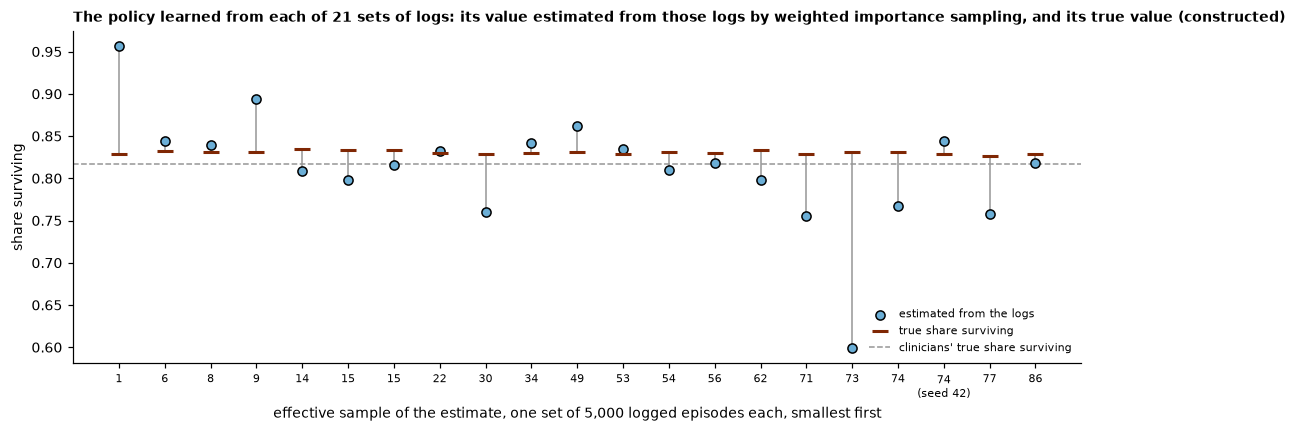

Effective sample across the 20 further sets of logs: 1.3 to 86.0 of 5,000 episodes. Estimate less truth: a tie: no detectable difference (the difference runs from -0.232 to +0.128 across 20 seeds). True value less the clinicians': higher: the difference runs from +0.009 to +0.017 across 20 seeds.


In [13]:
ts = rl.treatment_spread()
sets = pd.concat([pd.DataFrame({"naive": [out["naive"]["learned"].value], "true": [out["true"]["learned"]],
                                "ess": [out["naive"]["learned"].ess]}, index=[rl.EVAL_SEED]),
                  pd.DataFrame({"naive": ts["naive: learned"], "true": ts["true: learned"],
                                "ess": ts["effective sample: learned"]})]).sort_values("ess")
rest = sets.drop(index=rl.EVAL_SEED)
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(sets))
for k, (seed, row) in enumerate(sets.iterrows()):
    ax.plot([k, k], [row["true"], row["naive"]], color=GREY, linewidth=1)
ax.scatter(x, sets["naive"], color=PALE, edgecolor="black", s=36, zorder=3, label="estimated from the logs")
ax.scatter(x, sets["true"], color=DARK, marker="_", s=120, linewidth=2, zorder=3, label="true share surviving")
ax.axhline(ref["clinicians"], color=GREY, linestyle="--", linewidth=1, label="clinicians' true share surviving")
ax.set_xticks(x)
ax.set_xticklabels([f"{e:.0f}" + ("\n(seed 42)" if s == rl.EVAL_SEED else "") for s, e in sets["ess"].items()],
                   fontsize=7)
ax.set_xlabel("effective sample of the estimate, one set of 5,000 logged episodes each, smallest first")
ax.set_ylabel("share surviving")
ax.legend(fontsize=7, frameon=False, loc="lower right")
ax.set_title(f"The policy learned from each of {len(sets)} sets of logs: its value estimated from those logs by "
             f"weighted importance sampling, and its true value (constructed)", loc="left", fontsize=9)
plt.tight_layout()
plt.show()
print(f"Effective sample across the {len(rest)} further sets of logs: {rest['ess'].min():.1f} to "
      f"{rest['ess'].max():.1f} of {rl.LOGGED:,} episodes. Estimate less truth: "
      f"{rl.spread_words(rest['naive'] - rest['true'], 3)}. True value less the clinicians': "
      f"{rl.spread_words(rest['true'] - ref['clinicians'], 3)}.")

Two things hold at once. The learned policy is, in truth, a little better than the clinicians' on every set of logs: the process's record holds everything that drives the clinicians' doses and the outcomes, by construction, so the counts describe the process fairly. And its estimated value, the number a study from records would report, swings widely from one set of logs to the next around that truth, because each estimate rests on the few episodes whose every dose happened to match the policy's. The effective sample is how many episodes the estimate is worth: under a hundred, out of 5,000. That is E-119's second question: how large is the effective sample once only the patients treated as the new policy would treat them are counted. The further a policy departs from the logged care, the fewer episodes match it all the way through.

### A variable the learner sees and the clinicians did not

The response to a dose is read after the dose and filed against the step at which the dose was given: in this constructed record it reads 1 when the patient stayed or moved milder, read right nine times in ten, and 0 when no dose was given. The clinicians could not see it when they chose the dose; it did not yet exist. A learner reading the record sees it on the same row as the dose and treats it as known. E-120 lists the same kind of limitation: some laboratory values available to the algorithm would not have been available to clinicians at the time. E-119's first question asks whether the algorithm was given every variable that influenced the clinicians' decisions; this is the other side of it, a variable the algorithm was given that the clinicians did not have.

Below, the same logs are given to a second learner that also reads the response. Its value is estimated from the logs in the same way, reading the response as filed. Its true value is computed where the response is known only after the dose, so that at each step the policy reads the response to the previous dose.

In [14]:
leaky = out["leaky"]
print("Reading the response to the dose, the learner gives, at step 1 by severity 1 to 5:")
for r in (0, 1):
    print(f"  response {r}: " + ", ".join(rl.DOSES[a] for a in leaky.table[0, :, r]))
print(f"Seed {rl.EVAL_SEED}: estimated from the logs {out['naive']['learned, reading the response'].words()}; "
      f"true share surviving {out['true']['learned, reading the response']:.3f}, against the first learner's "
      f"{out['naive']['learned'].value:.3f} estimated and {out['true']['learned']:.3f} true.")
print(f"Across {len(ts)} further sets of logs, reading the response less not reading it:")
print(f"  estimated from the logs: {rl.spread_words(ts['naive: learned, reading the response'] - ts['naive: learned'], 3)}")
print(f"  true share surviving: {rl.spread_words(ts['true: learned, reading the response'] - ts['true: learned'], 3)}")

Reading the response to the dose, the learner gives, at step 1 by severity 1 to 5:
  response 0: none, none, moderate, intensive, intensive
  response 1: moderate, moderate, intensive, intensive, intensive
Seed 42: estimated from the logs 0.986, from 1,498 of 5,000 logged episodes with any weight, an effective sample of 26.8; true share surviving 0.830, against the first learner's 0.844 estimated and 0.829 true.
Across 20 further sets of logs, reading the response less not reading it:
  estimated from the logs: higher: the difference runs from +0.020 to +0.393 across 20 seeds
  true share surviving: a tie: no detectable difference (the difference runs from -0.022 to +0.002 across 20 seeds)


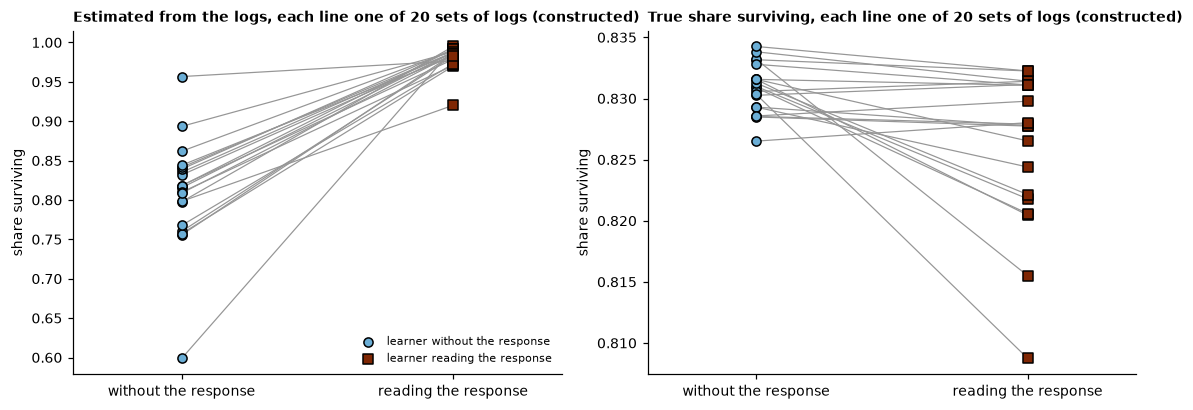

In [15]:
fig, (ax, bx) = plt.subplots(1, 2, figsize=(10.5, 3.8), sharey=False)
for i, (col, axis, title) in enumerate((("naive", ax, "Estimated from the logs"), ("true", bx, "True share surviving"))):
    a = ts[f"{col}: learned"].to_numpy()
    b = ts[f"{col}: learned, reading the response"].to_numpy()
    for k in range(len(a)):
        axis.plot([0, 1], [a[k], b[k]], color=GREY, linewidth=0.8)
    axis.scatter(np.zeros_like(a), a, color=PALE, edgecolor="black", zorder=3, label="learner without the response")
    axis.scatter(np.ones_like(b), b, color=DARK, marker="s", edgecolor="black", zorder=3,
                 label="learner reading the response")
    axis.set_xticks([0, 1])
    axis.set_xticklabels(["without the response", "reading the response"])
    axis.set_xlim(-0.4, 1.4)
    axis.set_ylabel("share surviving")
    axis.set_title(f"{title}, each line one of {len(a)} sets of logs (constructed)", loc="left", fontsize=9)
ax.legend(fontsize=7, frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

On the logs of seed 42, the learner that reads the response gives a dose at severities 1 and 2 only when the response says the patient stayed or improved; at severity 3 and above, where the logs hold no patient left without a dose, it gives one either way. In the logs that looks excellent. At severities 1 and 2 it matches the episodes where a moderate dose was followed by a good response and those where no dose was given, and passes over those where a dose was followed by a bad one. The estimate rises on every set of logs. But the response is the dose's own result. Where it is known only after the dose, the policy acts on the response to the previous dose, which adds nothing to what the current severity already says in this process, and its true value does not rise. The variable is not wrong; it is late.

### The trial of the same choice

E-120's learned policy recommended less fluid and more vasopressor than the clinicians gave. A trial and a cohort study bear on the same choice. Each row below is given as its source records it.

In [16]:
display(rl.claim_and_trial())

,what,who,result,how measured
source,,,,
E-120,"a policy learned from records, scored from records","trained on 17,083 admissions from one hospital's database, tested on 79,073 from 128 hospitals",estimated value 84.5 for the learned policy against 56.9 for clinicians; vasopressors recommended 30% of the time against 17% given,weighted importance sampling on records; the authors state it needs prospective evaluation
E-97,a trial of two fixed strategies: restrictive against liberal fluid,"1,563 patients, 60 US centres","death by 90 days 14.0% (restrictive) against 14.9% (liberal); difference -0.9 points (-4.4 to 2.6), P=.61; the restrictive group received a median 2,134 mL less fluid",a trial
E-94,time to each treatment,"49,331 patients, 149 New York hospitals","odds ratio for death for each hour to antibiotics 1.04 (1.03-1.06); for each hour to the fluid bolus 1.01 (0.99-1.02), not associated",observational


CLOVERS (E-97), a trial, tested two fixed strategies, restrictive against liberal fluid, and found a difference in death by 90 days of less than one point, with an interval from 4.4 points fewer to 2.6 more. The timing study (E-94), observational, found each hour to antibiotics associated with higher odds of death and each hour to the fluid bolus not associated. Neither tested what E-120's policy is: an adaptive policy, choosing a dose for each patient at each step. A trial of two fixed strategies does not refute an adaptive one. Nor does E-120 show that patients do better under its policy: its 84.5 against 56.9 is an estimate from records by weighted importance sampling, the method whose behaviour on the constructed process is shown above, and its authors state that the policy needs prospective evaluation.

The notebook's own reading, not a finding of any source: if a two-litre difference in fluid between two fixed strategies moved death by 90 days by less than a point, a claim that a policy pulling the same levers more cleverly saves many more lives needs strong evidence. That is a prior to start from, not a proof that the policy is wrong.

### A question about the benchmark

ICU-Sepsis (E-49) is a published benchmark with 716 states and 25 actions, built from MIMIC-III and not to guide practice. A random policy scores 0.78, the estimated clinician policy 0.78 and the best policy 0.88; the dataset average is 0.77. These are published figures; nothing here was run on it.

**A question to put to yourself.** In that model, the clinicians' estimated policy scores no better than choosing at random. Is that a finding about the clinicians, or about the model? What would a model have to leave out of a patient's state for the two to score the same? The constructed process gives its own three numbers below; they answer nothing about ICU-Sepsis, and neither benchmark says anything about a patient.

In [17]:
print(f"Constructed process, from its own tables: random {ref['random']:.3f}, clinicians {ref['clinicians']:.3f}, "
      f"best {ref['best']:.3f}.")
print(f"ICU-Sepsis, as published (E-49): random {rl.E49['random']}, estimated clinician policy {rl.E49['clinician']}, "
      f"optimal {rl.E49['optimal']}, on {rl.E49['states']} states and {rl.E49['actions']} actions.")

Constructed process, from its own tables: random 0.775, clinicians 0.817, best 0.834.
ICU-Sepsis, as published (E-49): random 0.78, estimated clinician policy 0.78, optimal 0.88, on 716 states and 25 actions.


## The failure: doing nothing wins on the scoreboard

Now score a policy that gives no dose at any step, from the same logs and by the same method. This is the answer to the hook.

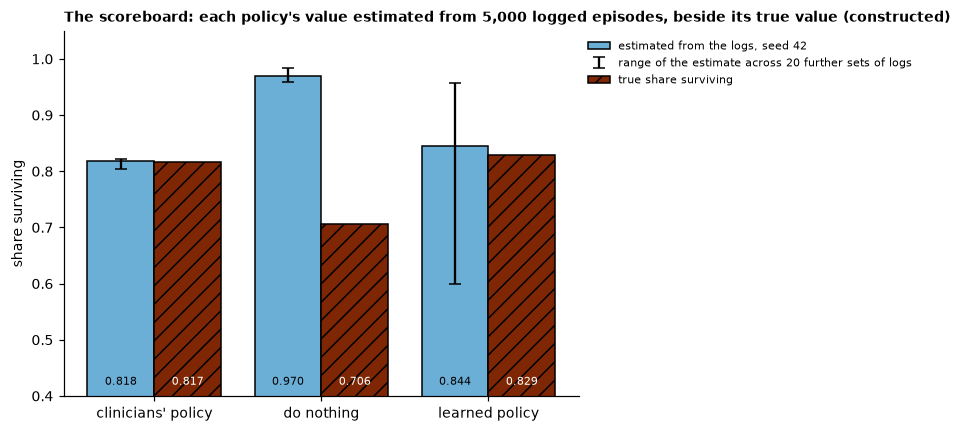

Across 20 further sets of logs, estimated from the logs:
  doing nothing less the clinicians: higher: the difference runs from +0.140 to +0.171 across 20 seeds
  doing nothing less the learned policy: higher: the difference runs from +0.016 to +0.380 across 20 seeds
True, from the process's own tables: doing nothing 0.706 against the clinicians' 0.817: 11.1 fewer survive in every 100 patients.


In [18]:
names = ("clinicians", "do nothing", "learned")
fig, ax = plt.subplots(figsize=(8.5, 4))
x = np.arange(len(names))
naive = [out["naive"][n].value for n in names]
true = [out["true"][n] for n in names]
lo = [ts[f"naive: {n}"].min() for n in names]
hi = [ts[f"naive: {n}"].max() for n in names]
ax.bar(x - 0.2, naive, width=0.4, color=PALE, edgecolor="black", label=f"estimated from the logs, seed {rl.EVAL_SEED}")
ax.errorbar(x - 0.2, naive, yerr=[np.subtract(naive, lo).clip(0), np.subtract(hi, naive).clip(0)], fmt="none",
            ecolor="black", capsize=4, label=f"range of the estimate across {len(ts)} further sets of logs")
ax.bar(x + 0.2, true, width=0.4, color=DARK, edgecolor="black", hatch="//", label="true share surviving")
for i in range(len(names)):
    ax.text(x[i] - 0.2, 0.42, f"{naive[i]:.3f}", ha="center", fontsize=7)
    ax.text(x[i] + 0.2, 0.42, f"{true[i]:.3f}", ha="center", fontsize=7, color="white")
ax.set_xticks(x)
ax.set_xticklabels(["clinicians' policy", "do nothing", "learned policy"])
ax.set_ylim(0.4, 1.05)
ax.set_ylabel("share surviving")
ax.legend(fontsize=7, frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))
ax.set_title("The scoreboard: each policy's value estimated from 5,000 logged episodes, beside its true value "
             "(constructed)", loc="left", fontsize=9)
plt.tight_layout()
plt.show()
print(f"Across {len(ts)} further sets of logs, estimated from the logs:")
print(f"  doing nothing less the clinicians: {rl.spread_words(ts['naive: do nothing'] - ts['naive: clinicians'], 3)}")
print(f"  doing nothing less the learned policy: {rl.spread_words(ts['naive: do nothing'] - ts['naive: learned'], 3)}")
print(f"True, from the process's own tables: doing nothing {ref['do nothing']:.3f} against the clinicians' "
      f"{ref['clinicians']:.3f}: {100 * (ref['clinicians'] - ref['do nothing']):.1f} fewer survive in every 100 patients.")

Doing nothing scores above the clinicians and above the learned policy when scored from the logs, on every one of the 20 further sets, and is the worst of the three in truth: fewer survive than under the clinicians' policy. The reason is in the weights.

,episodes,with any weight,share of the weight,share surviving
worst severity reached,,,,
1,585,420,0.395,1.000
2,1084,210,0.605,0.949
3,1305,0,0.000,0.877
4,1083,0,0.000,0.744
5,943,0,0.000,0.559


Doing nothing, estimated from the logs: 0.970, from 630 of 5,000 logged episodes with any weight, an effective sample of 262.2.


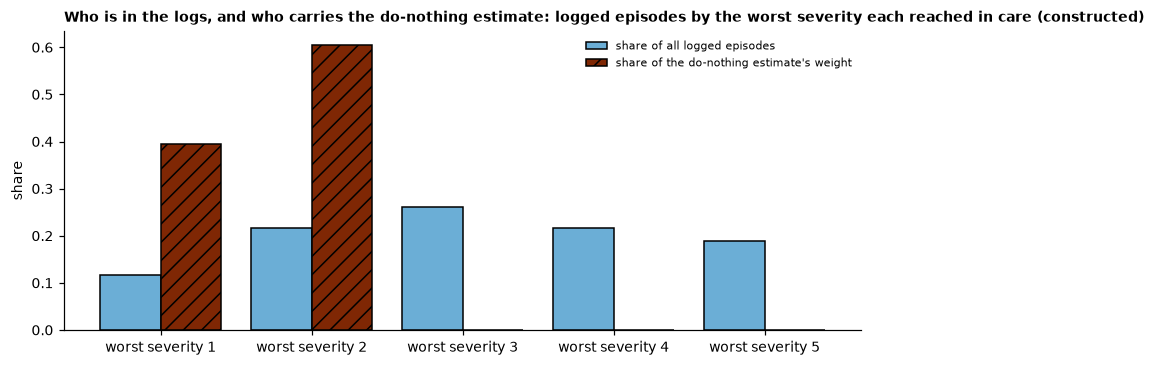

In [19]:
carry = rl.who_carries()
display(carry.round(3))
est = out["naive"]["do nothing"]
print(f"Doing nothing, estimated from the logs: {est.words()}.")
fig, ax = plt.subplots(figsize=(8, 3.4))
x = np.arange(rl.S)
ax.bar(x - 0.2, carry["episodes"] / carry["episodes"].sum(), width=0.4, color=PALE, edgecolor="black",
       label="share of all logged episodes")
ax.bar(x + 0.2, carry["share of the weight"], width=0.4, color=DARK, edgecolor="black", hatch="//",
       label="share of the do-nothing estimate's weight")
ax.set_xticks(x)
ax.set_xticklabels([f"worst severity {s}" for s in rl.SEVERITIES])
ax.set_ylabel("share")
ax.legend(fontsize=7, frameon=False)
ax.set_title("Who is in the logs, and who carries the do-nothing estimate: logged episodes by the worst severity "
             "each reached in care (constructed)", loc="left", fontsize=9)
plt.tight_layout()
plt.show()

Importance sampling counts a logged episode only if every dose in it is one the policy being scored would give. For doing nothing, that means episodes in which no dose was ever given. In this constructed process the clinicians always give a dose at severity 3 and above, an assumption, so every patient who reached severity 3 was dosed and carries no weight. The episodes left are those of patients who never became worse than severity 2, and nearly all of them survived. The estimate is their share surviving, weighted. The patients that doing nothing would have harmed, those who got worse and were left untreated, do not exist in the logs, because nobody left them untreated; the weights cannot count what was never recorded.

E-50 records the same mechanism in the original work: evaluation by importance sampling gives almost no weight to trajectories where the learned policy departs from the clinicians, so a policy of withholding treatment can score well, and a zero-drug policy beat the clinician policy in most of the critics' reproductions. Here the weight is not almost none but none, because the constructed clinicians never withhold a dose at the higher severities.

Go back to the guess. On the constructed process, the scoring method is what went wrong: it was asked about patients it had no record of, and it answered with the patients it had. E-50 places the hook's result in the same place: in how the policies were scored.

## Scorecard

The scorecard has seven axes (D-21). Axes 1, 2 and 6 are computed and carry the **mechanism** label; axes 3, 4 and 5 are stated; axis 7 is net benefit at a threshold of 0.10 for every lens (D-26). Net benefit judges a model by its consequences, at a threshold probability that encodes how a false alarm is weighed against a miss (E-93); here it is computed per 100 casualties as those correctly flagged less those wrongly flagged, the second weighted by the threshold over one minus it, and set beside flagging every casualty and flagging none, which scores zero.

The diagnosis column is the question policy, scored on the 100,000 synthetic casualties of the military cohort (seed 42), every stream, against need for a life-saving intervention. Fit is weak. Its probability is the share in need among the training casualties who gave the same answers. The baseline is the MPTT-24 read as its figure was published, with the text reading beside it, labelled as validated (D-24); a rule gives no probability, so its Brier score is the share misclassified. The setting changes only the scan, which none of them reads, so axis 6 is unchanged for all three. The treatment column is the learned policy on the constructed process; fit is native. It is not a classifier, so axes that score a flag are answered in words, and the rule states no treatment policy, so the treatment rows hold no baseline figure (NaN). Spreads are across 20 further samples or sets of logs.

In [20]:
display(rl.seven_axes())

,diagnosis: which question next (weak fit),"baseline: MPTT-24, figure (as published)","baseline: MPTT-24, text (as validated)","treatment: learned policy, constructed decision process"
axis,,,,
1 Discrimination (mechanism),"sensitivity 88.4%, specificity 40.2% for need for a life-saving intervention, on 100,000 synthetic casualties, 16,704 in need. Sensitivity less the rule's (figure): higher: the difference runs from +0.282 to +0.295 across 20 seeds; specificity less the rule's: lower: the difference runs from -0.385 to -0.380 across 20 seeds. Its decisions rest on two assumptions: a miss weighed 9 times a false alarm, and a question costing 0.01 of a false alarm","sensitivity 60.0%, specificity 78.6%. The scorecard's figures are on every stream of the military cohort, disease included; the comparison with E-09 holds for the injured only, of whom 26.5% need a life-saving intervention against 47.6% Priority 1 in the military registry (E-09), so the generator's injured are a milder cohort than the one the rule was validated on (D-23). The generator's physiology is an assumption, tuned until the rule landed within 0.05 of E-09's accuracy, which was measured on first recorded hospital respiratory rate and registry GCS, not at the point of injury","sensitivity 61.4%, specificity 77.8%","Not a classifier: the learned policy's true share surviving is 0.829 on the logs of seed 42, from 0.827 to 0.834 across 20 further sets of logs; the clinicians' policy 0.817, doing nothing 0.706, the best policy 0.834 (constructed decision process). Learned less clinicians: higher: the difference runs from +0.009 to +0.017 across 20 seeds. The process's record holds everything that drives the clinicians' doses and the outcomes, by construction"
2 Calibration (mechanism),"Brier 0.131, where lower is better; share in need where it stopped minus share in need -0.0001. That gap less the rule's share flagged minus share in need (figure), every stream, is lower: the difference runs from -0.112 to -0.107 across 20 seeds. Its Brier score less the rule's (figure), every stream, is lower: the difference runs from -0.116 to -0.110 across 20 seeds. Among battle casualties alone this reverses: its Brier score is 0.327 against the rule's 0.318, and the difference is higher: the difference runs from +0.002 to +0.013 across 20 seeds. Its shares in need are counted on every stream of the training sample; among battle casualties they fall 0.312 below the share in need, where the rule's share flagged falls 0.057 below it; the policy's gap less the rule's is lower: the difference runs from -0.258 to -0.250 across 20 seeds","Brier 0.245, where lower is better; it flags 11.2 points more than are in need. A rule gives no probability, so the Brier score is the share misclassified","Brier 0.249, where lower is better; it flags 12.1 points more than are in need. A rule gives no probability, so the Brier score is the share misclassified",Of the value estimate from logs: naive estimate less true value across 20 further sets of logs. Learned policy: a tie: no detectable difference (the difference runs from -0.232 to +0.128 across 20 seeds). Doing nothing: higher: the difference runs from +0.253 to +0.279 across 20 seeds. Learned while reading the response to each dose: higher: the difference runs from +0.089 to +0.183 across 20 seeds
3 Uncertainty expressed,"A share in need where it stops, counted on the training sample; no interval",None: a priority,None: a priority,"One estimate from one set of logs, with its effective sample size: for the learned policy 74.4 of 5,000 episodes on seed 42, from 1.3 to 86.0 across 20 further sets of logs. No interval"
4 What it needed,"Labelled cases: 100,000 synthetic training casualties with need known; two stated costs, both assumptions",Rules only (E-08),Rules only (E-08),"5,000 logged episodes of the clinicians' policy, with every dose and the recorded severity; no free interaction. The true value needs the process's own tables, which onl

In [21]:
card = pd.DataFrame([vars(row) for row in rl.LENS.scorecard()])
card[["case", "metric", "value", "baseline", "label", "fit", "data_source"]]

,case,metric,value,baseline,label,fit,data_source
0,diagnosis,"sensitivity, question policy's flag against need for a life-saving intervention, every stream, scan before hospital",8.843e-01,0.600,mechanism,weak,generator
1,diagnosis,"specificity, question policy's flag against need for a life-saving intervention, every stream, scan before hospital",4.023e-01,0.786,mechanism,weak,generator
2,diagnosis,"Brier score, where lower is better, question policy's flag against need for a life-saving intervention, every stream, scan before hospital",1.311e-01,0.245,mechanism,weak,generator
3,diagnosis,"share in need where it stopped minus share in need, question policy's flag against need for a life-saving intervention, every stream, scan before hospital",-1.000e-04,0.112,mechanism,weak,generator
4,diagnosis,"sensitivity, question policy's flag against need for a life-saving intervention, every stream, scan in hospital",8.843e-01,0.600,mechanism,weak,generator
5,diagnosis,"specificity, question policy's flag against need for a life-saving intervention, every stream, scan in hospital",4.023e-01,0.786,mechanism,weak,generator
6,diagnosis,"Brier score, where lower is better, question policy's flag against need for a life-saving intervention, every stream, scan in hospital",1.311e-01,0.245,mechanism,weak,generator
7,diagnosis,"share in need where it stopped minus share in need, question policy's flag against need for a life-saving intervention, every stream, scan in hospital",-1.000e-04,0.112,mechanism,weak,generator
8,treatment,"true value of the learned policy, constructed decision process, 5,000 logged episodes, seed 42, share surviving",8.286e-01,NaN,mechanism,native,constructed decision process
9,treatment,"naive estimate less true value: learned, constructed decision process, 5,000 logged episodes, seed 42, share surviving",1.580e-02,NaN,mechanism,native,constructed decision process


Two rows carry the lesson.

**Diagnosis.** A policy that chooses its own questions beats the rule on net benefit at 0.10 on every sample, because it was built to minimise the expected cost that net benefit at 0.10 scores, on the generator's synthetic casualties. It does so by flagging most of those not in need, and among battle casualties its Brier score is worse than the rule's. The win belongs to the costs and the generator as much as to the method.

**Treatment.** Estimated from logs, the learned policy's value swings widely from one set of logs to the next on under a hundred effective episodes, and doing nothing is estimated far above its true value on every set. The true values are known only because the process is constructed.

**Teach back.** In one sentence, why can a policy that withholds treatment score well when it is scored only from records of patients who were treated?

## The brain analogy, and where it breaks

**What it resembles.** Dopamine as a reward prediction error. Dopamine neuron firing tracks the difference between the reward expected and the reward received (E-56). The Bellman equation has a gap of the same shape: the value expected from a state, set against what one step and the value of the next state turn out to give. A learner that moves its values to close that gap is learning from prediction errors.

**Where it breaks.** Only the abstract of E-56 was read. It supports a prediction error signal, not a full learning algorithm, and the link to temporal-difference learning made in the full paper is not relied on here. Nothing in this notebook learns the way a brain might: the learner counts records and solves a table backwards, and no neuron is claimed to do that. The analogy is also silent on this notebook's lesson, which is about scoring. A learner driven by its own prediction errors would still be judged by someone, and could still learn to please the judge.